# Exploración de MiBici | Equipo 45

**Autor:** Leonardo Peraza Alavez. Este notebook describe los datos y las variables. La ingesta, las transformaciones reutilizables y el entrenamiento permanecen en `mibici/`.

Se usan conteos globales del manifiesto para describir cobertura. La exploración de objetivos, correlaciones y perfiles se limita a entrenamiento; validación y prueba se reservan para evaluar los modelos. No se muestran viajes ni atributos personales.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "mibici").is_dir())
sys.path.insert(0, str(ROOT))
from mibici import config as cfg

plt.switch_backend("module://matplotlib_inline.backend_inline")
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 10})
manifest = json.loads(cfg.MANIFEST_PATH.read_text())
variables = json.loads(cfg.FEATURE_MANIFEST_PATH.read_text())
cfg.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
display(pd.DataFrame([manifest["summary"]]))

,months,raw_rows,clean_trips,observed_stations,catalog_stations,stations_outside_catalog
0,9,3362065,3358273,471,480,"[405, 407]"


## 1. Cobertura y calidad

Los nueve meses no cubren un ciclo anual. El catálogo de septiembre es una referencia estática y no demuestra la capacidad histórica de cada estación. Los descartes se documentan por archivo.

,month,raw_rows,clean_rows,invalid,duplicates
0,2026-01,357180,356918,262,0
1,2026-02,333756,331893,1863,0
2,2026-03,376243,376028,215,0
3,2026-04,351851,351689,162,0
4,2026-05,315895,315819,76,0
5,2026-06,355303,355187,116,0
6,2026-07,388257,388175,82,0
7,2026-08,393524,393437,87,0
8,2026-09,490056,489127,171,758


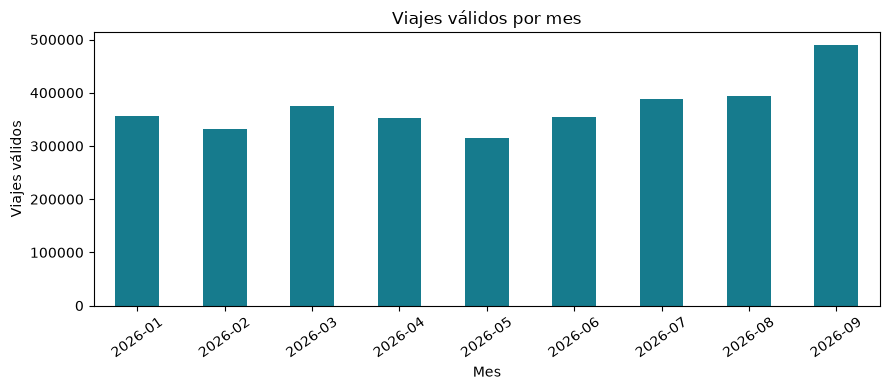

In [2]:
monthly = pd.DataFrame(manifest["trips"])[["month", "raw_rows", "clean_rows", "invalid", "duplicates"]]
display(monthly)
ax = monthly.set_index("month")["clean_rows"].plot.bar(color="#167b8d")
ax.set(xlabel="Mes", ylabel="Viajes válidos", title="Viajes válidos por mes")
plt.xticks(rotation=35)
plt.tight_layout()
plt.savefig(cfg.FIGURES_DIR / "eda_viajes_mensuales.png", dpi=160)
plt.show()

## 2. Estructura y tipos

Se revisa enero, perteneciente a entrenamiento. El esquema limpio tiene cinco campos: ID del viaje, inicio, fin, estación de origen y destino. Los identificadores no se usan como predictores del modelo.

In [3]:
january = pd.read_parquet(cfg.DATA_DIR / manifest["trips"][0]["clean_path"])
display(january.dtypes.astype(str).rename("tipo").to_frame())
duration = (january["ended_at"] - january["started_at"]).dt.total_seconds() / 60
display(duration.describe(percentiles=[0.5, 0.9, 0.99]).rename("minutos").to_frame())
print("Faltantes en el mes limpio:", int(january.isna().sum().sum()))
print("IDs duplicados en el mes limpio:", int(january.trip_id.duplicated().sum()))

,tipo
trip_id,int64
started_at,"datetime64[us, America/Mexico_City]"
ended_at,"datetime64[us, America/Mexico_City]"
origin_id,int32
destination_id,int32


,minutos
count,356918.000000
mean,11.173727
std,8.949708
min,0.016667
50%,9.616667
90%,20.816667
99%,32.466667
max,1185.083333


Faltantes en el mes limpio: 0
IDs duplicados en el mes limpio: 0


La gráfica siguiente limita el eje al percentil 99 para que se vea la distribución habitual. Esto solo modifica la visualización: no elimina viajes de duración positiva del dataset.

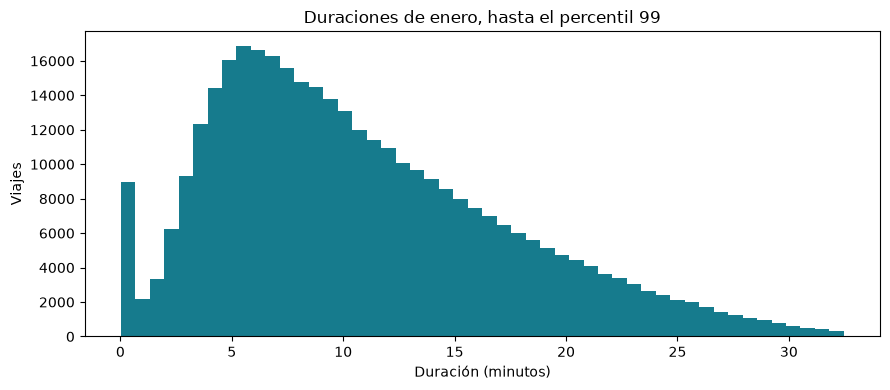

In [4]:
duration[duration <= duration.quantile(0.99)].plot.hist(bins=50, color="#167b8d")
plt.xlabel("Duración (minutos)")
plt.ylabel("Viajes")
plt.title("Duraciones de enero, hasta el percentil 99")
plt.tight_layout()
plt.show()
del january

## 3. Demanda horaria de entrenamiento

Los rezagos y medias se generan por estación usando horas anteriores. Las horas cero se completan después de la primera actividad observada, bajo el supuesto de operación continua; no identifican por sí mismas cierres o fallas de registro.

,hour,weekday,is_weekend,month,departures_lag_1,departures_lag_24,departures_lag_168,departures_mean_24,departures_mean_168,target_departures
count,1552105.000,1552105.000,1552105.000,1552105.000,1552105.000,1552105.000,1552105.00,1552105.000,1552105.000,1552105.000
mean,11.514,3.005,0.288,3.640,1.301,1.300,1.29,1.299,1.297,1.301
std,6.921,2.007,0.453,1.673,2.475,2.475,2.47,1.387,1.285,2.475
min,0.000,0.000,0.000,1.000,0.000,0.000,0.00,0.000,0.000,0.000
25%,6.000,1.000,0.000,2.000,0.000,0.000,0.00,0.417,0.464,0.000
50%,12.000,3.000,0.000,4.000,0.000,0.000,0.00,0.875,0.946,0.000
75%,18.000,5.000,1.000,5.000,2.000,2.000,2.00,1.750,1.702,2.000
max,23.000,6.000,1.000,6.000,149.000,149.000,149.00,27.333,14.690,149.000


Filas de entrenamiento: 1552105
Fracción de horas sin salidas: 0.5452


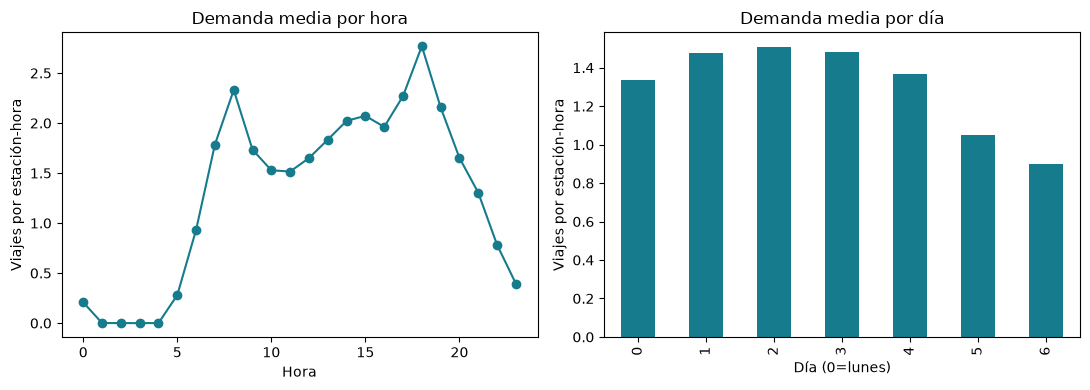

In [5]:
p1 = pd.read_parquet(cfg.FEATURE_FILES["p1"])
training = p1.loc[p1["split"] == "train"].copy()
display(training[[*cfg.P1_FEATURE_COLUMNS, "target_departures"]].describe().round(3))
print("Filas de entrenamiento:", len(training))
print("Fracción de horas sin salidas:", round(training.target_departures.eq(0).mean(), 4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
training.groupby("hour").target_departures.mean().plot(ax=axes[0], marker="o", color="#167b8d")
axes[0].set(title="Demanda media por hora", xlabel="Hora", ylabel="Viajes por estación-hora")
training.groupby("weekday").target_departures.mean().plot.bar(ax=axes[1], color="#167b8d")
axes[1].set(title="Demanda media por día", xlabel="Día (0=lunes)", ylabel="Viajes por estación-hora")
fig.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "eda_demanda_entrenamiento.png", dpi=160)
plt.show()

## 4. Relaciones entre variables

Las correlaciones siguientes son descriptivas y se calculan solo en entrenamiento. No prueban causalidad ni sustituyen la comparación con un baseline en validación.

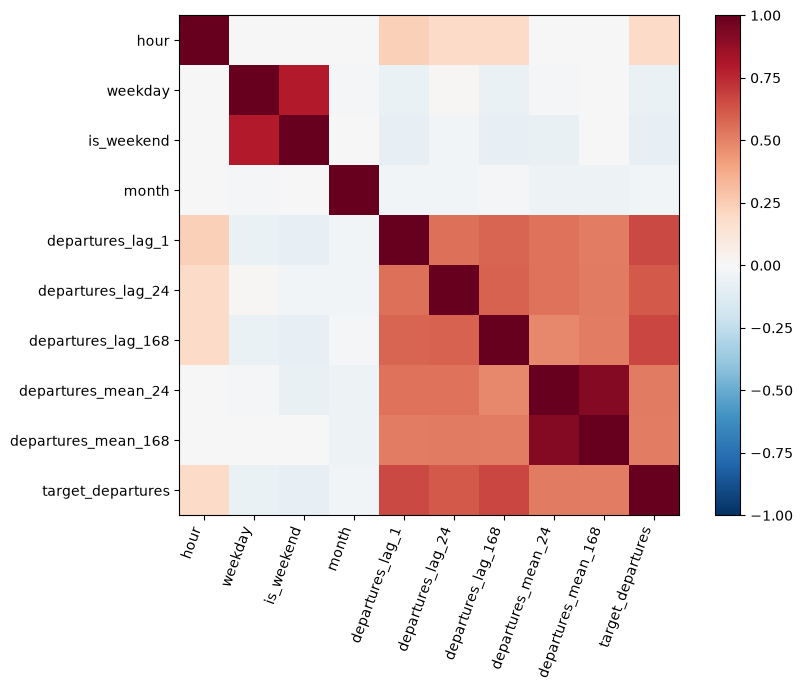

In [6]:
columns = [*cfg.P1_FEATURE_COLUMNS, "target_departures"]
corr = training[columns].corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(columns)), columns, rotation=70, ha="right")
ax.set_yticks(range(len(columns)), columns)
fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()
del p1, training

## 5. Clases del riesgo virtual

Estas etiquetas se derivan de un inventario simulado. Su distribución y las métricas de clasificación describen ese escenario, no faltantes de bicicletas observados realmente.

,filas,proporcion
normal,830469,0.535290
riesgo_sin_bicicletas,521323,0.336026
riesgo_sin_anclajes,199645,0.128684


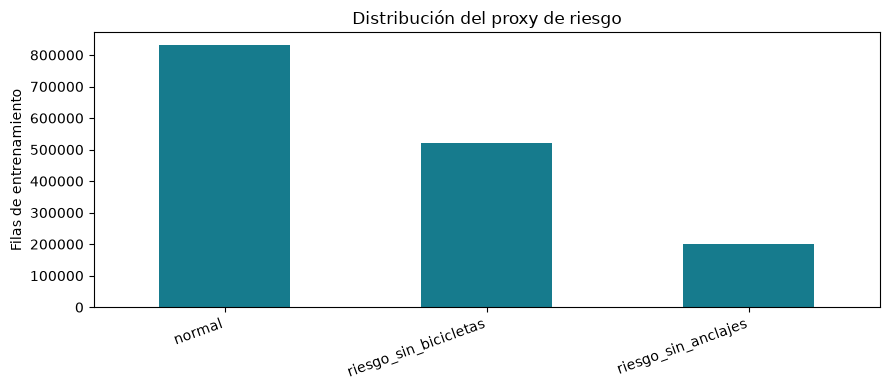

In [7]:
p2 = pd.read_parquet(cfg.FEATURE_FILES["p2"], columns=["split", "target_risk"])
counts = p2.loc[p2["split"] == "train", "target_risk"].value_counts().sort_index()
counts.index = [cfg.P2_CLASS_NAMES[int(value)] for value in counts.index]
display(pd.DataFrame({"filas": counts, "proporcion": counts / counts.sum()}))
counts.plot.bar(color="#167b8d")
plt.ylabel("Filas de entrenamiento")
plt.title("Distribución del proxy de riesgo")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()
del p2

## 6. Perfiles para agrupar estaciones

Cada estación tiene 48 medias horarias normalizadas: 24 laborales y 24 de fin de semana. Se exige cobertura mínima. Las coordenadas se conservan para representar los grupos en un mapa y no entran al clustering.

Estaciones con perfil de entrenamiento: 397
Máximo error de normalización: 7.771561172376096e-16


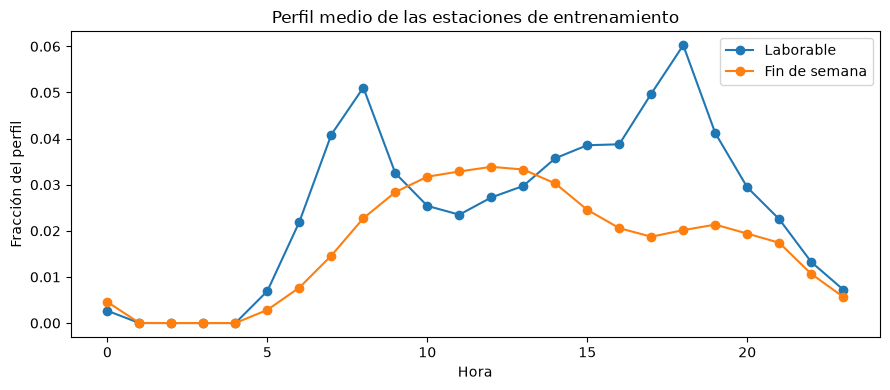

In [8]:
profiles = pd.read_parquet(cfg.FEATURE_FILES["p3_train"])
print("Estaciones con perfil de entrenamiento:", len(profiles))
print("Máximo error de normalización:", float((profiles[list(cfg.P3_FEATURE_COLUMNS)].sum(axis=1) - 1).abs().max()))
for kind, label in [("weekday", "Laborable"), ("weekend", "Fin de semana")]:
    means = profiles[[f"{kind}_{hour:02d}" for hour in range(24)]].mean()
    plt.plot(range(24), means, marker="o", label=label)
plt.xlabel("Hora")
plt.ylabel("Fracción del perfil")
plt.title("Perfil medio de las estaciones de entrenamiento")
plt.legend()
plt.tight_layout()
plt.show()

## Decisiones para el modelado

- Comparar P1 con la misma hora de la semana anterior y usar MAE, RMSE y WAPE; las horas cero hacen poco conveniente MAPE.
- Balancear las clases de P2 y evaluar F1 macro y recall por clase, manteniendo explícito que la etiqueta es un proxy.
- Normalizar los perfiles de P3 para comparar formas y contrastar estabilidad entre periodos.
- Mantener la partición temporal; cualquier escalado se ajusta solo con entrenamiento.
- Ejecutar los modelos desde `python -m mibici.train`, registrar versiones y conservar los datos fuera de Git.

Fuentes y limitaciones: [propuesta](../references/propuesta.md), [condiciones de los datos](../references/condiciones_datos.md) y [protocolo](../references/protocolo_experimento.md).